# Phase 2.1 — Dataset Inspection
## PAIMANA ML Prediction System

### Overview & Non-Destructive Inspection Rules
This notebook performs an exhaustive, **read-only** inspection of the primary machine learning feature dataset (`PAIMANA_Cleaned_ML_Features.csv`) and compares its structural characteristics with the secondary dashboard dataset (`PAIMANA_Filtered_2017onwards_Cleaned.csv`).

**Inspection Protocol & Safety Guardrails:**
- **Read-Only**: No data cleaning, transformation, filtering, column renaming, or row deletion is performed.
- **No Target Creation**: The target variable `Future_Delay_3M` is **not** created in this phase.
- **No ML Modeling**: No models are trained, scaled, or evaluated.
- **Strict Evidence Gathering**: The sole purpose is to establish factual ground truth regarding data types, snapshot intervals, status transitions, missingness, and leakage risks to rigorously inform the Phase 2.2 target definition.

In [1]:
# 1. Setup & Environment
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

# Robust path resolution
if os.path.exists('../data/raw/PAIMANA_Cleaned_ML_Features.csv'):
    DATA_DIR = '../data/raw'
    REPORTS_DIR = '../reports'
elif os.path.exists('data/raw/PAIMANA_Cleaned_ML_Features.csv'):
    DATA_DIR = 'data/raw'
    REPORTS_DIR = 'reports'
elif os.path.exists('../../data/raw/PAIMANA_Cleaned_ML_Features.csv'):
    DATA_DIR = '../../data/raw'
    REPORTS_DIR = '../../reports'
else:
    raise FileNotFoundError("Could not find data/raw directory.")

os.makedirs(REPORTS_DIR, exist_ok=True)

PRIMARY_DATASET_PATH = os.path.join(DATA_DIR, 'PAIMANA_Cleaned_ML_Features.csv')
SECONDARY_DATASET_PATH = os.path.join(DATA_DIR, 'PAIMANA_Filtered_2017onwards_Cleaned.csv')
COLUMN_INVENTORY_REPORT_PATH = os.path.join(REPORTS_DIR, 'column_inventory.csv')

print(f"Primary Dataset Path: {PRIMARY_DATASET_PATH}")
print(f"Secondary Dataset Path: {SECONDARY_DATASET_PATH}")
print(f"Column Inventory Output: {COLUMN_INVENTORY_REPORT_PATH}")

Primary Dataset Path: data/raw\PAIMANA_Cleaned_ML_Features.csv
Secondary Dataset Path: data/raw\PAIMANA_Filtered_2017onwards_Cleaned.csv
Column Inventory Output: reports\column_inventory.csv


## 2. Load Primary Dataset
Loading `PAIMANA_Cleaned_ML_Features.csv` using pandas with `low_memory=False` and UTF-8 encoding.

In [2]:
# Load primary dataset
df_primary = pd.read_csv(PRIMARY_DATASET_PATH, encoding='utf-8', low_memory=False)

print(f"Primary Dataset Dimensions: {df_primary.shape[0]:,} rows x {df_primary.shape[1]} columns\n")

# Display First 10 Rows
print("--- First 10 Rows ---")
display(df_primary.head(10))

# Display Last 10 Rows
print("--- Last 10 Rows ---")
display(df_primary.tail(10))

# Column names and Data Types
print("--- Column Names & Data Types ---")
dtypes_df = pd.DataFrame({
    'Column Name': df_primary.columns,
    'Data Type': df_primary.dtypes.astype(str)
}).reset_index(drop=True)
display(dtypes_df)

Primary Dataset Dimensions: 93,217 rows x 50 columns

--- First 10 Rows ---


,Project Code,Project Name,Sector,Agency / Implementing Organisation,State / Location,Start Date / DOA,Report Date / Snapshot Date,Project Status,Original Cost (Rs. crore),Revised Cost (Rs. crore),Anticipated Cost (Rs. crore),Cumulative Expenditure (Rs. crore),Original Commissioning Date,Revised Commissioning Date,Anticipated Commissioning Date,Milestones,Physical Progress (%),Project Age (months),Original Duration (months),Anticipated Duration (months),Time Remaining to Anticipated Completion (months),Commissioning Slippage (months),Cost Escalation (%),Anticipated Cost Increase (%),Expenditure vs Original Cost (%),Previous Progress (%),Progress 2 Snapshots Ago (%),Progress 3 Snapshots Ago (%),Previous Expenditure (Rs. crore),Expenditure 2 Snapshots Ago (Rs. crore),Expenditure 3 Snapshots Ago (Rs. crore),Snapshot Gap (days),Progress Change (percentage points),Expenditure Change (Rs. crore),Progress Velocity (percentage points/month),Expenditure Velocity (Rs. crore/month),Expenditure Growth (%),Previous 3-Snapshot Avg Progress (%),Previous 3-Snapshot Avg Expenditure (Rs. crore),Previous 6-Snapshot Avg Progress (%),Previous 6-Snapshot Avg Expenditure (Rs. crore),Progress Acceleration (percentage points/month²),Expenditure-to-Progress Ratio,Physical Progress (%) Missing,Cumulative Expenditure (Rs. crore) Missing,Revised Cost (Rs. crore) Missing,Anticipated Cost (Rs. crore) Missing,State / Location Missing,Sector Missing,Agency / Implementing Organisation Missing
0,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-04-01,ONGOING,3492.0,NaN,6840.0,5771.17,2010-09-01,NaN,2021-10-01,NaN,NaN,187.0,84.0,217.0,30.0,NaN,NaN,95.876289,165.268328,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1,0,1,0,0
1,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-05-01,ONGOING,3492.0,NaN,6840.0,5784.74,2010-09-01,NaN,2021-10-01,NaN,NaN,188.0,84.0,217.0,29.0,NaN,NaN,95.876289,165.656930,NaN,NaN,NaN,5771.17,NaN,NaN,30.0,NaN,13.57,NaN,13.767896,0.235134,NaN,5771.170000,NaN,5771.170000,NaN,NaN,1,0,1,0,1,0,0
2,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-06-01,ONGOING,3492.0,NaN,6840.0,5784.74,2010-09-01,NaN,2021-10-01,NaN,NaN,189.0,84.0,217.0,28.0,NaN,NaN,95.876289,165.656930,NaN,NaN,NaN,5784.74,5771.17,NaN,31.0,NaN,0.00,NaN,0.000000,0.000000,NaN,5777.955000,NaN,5777.955000,NaN,NaN,1,0,1,0,1,0,0
3,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-07-01,ONGOING,3492.0,NaN,6840.0,5784.74,2010-09-01,NaN,2021-10-01,NaN,NaN,190.0,84.0,217.0,27.0,NaN,NaN,95.876289,165.656930,NaN,NaN,NaN,5784.74,5784.74,5771.17,30.0,NaN,0.00,NaN,0.000000,0.000000,NaN,5780.216667,NaN,5780.216667,NaN,NaN,1,0,1,0,1,0,0
4,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-08-01,ONGOING,3492.0,NaN,6840.0,5784.74,2010-09-01,NaN,2021-10-01,NaN,NaN,191.0,84.0,217.0,26.0,NaN,NaN,95.876289,165.656930,NaN,NaN,NaN,5784.74,5784.74,5784.74,31.0,NaN,0.00,NaN,0.000000,0.000000,NaN,5784.740000,NaN,5781.347500,NaN,NaN,1,0,1,0,1,0,0
5,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-09-01,ONGOING,3492.0,NaN,6840.0,5821.38,2010-09-01,NaN,2021-10-01,NaN,NaN,192.0,84.0,217.0,25.0,NaN,NaN,95.876289,166.706186,NaN,NaN,NaN,5784.74,5784.74,5784.74,31.0,NaN,36.64,NaN,35.975161,0.633391,NaN,5784.740000,NaN,5782.026000,NaN,NaN,1,0,1,0,1,0,0
6,020100044,PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE),ATOMIC ENERGY,"BHAVNI,TAMIL NADU",UNKNOWN,2003-09-01,2019-10-01,ONGOING,3492.0,NaN,6840.0,5830.42,2010-09-01,NaN,2021-10-01,NaN,NaN,193.0,84.0,217.0,24.0,NaN,NaN,95.876289,166.965063,NaN,NaN,NaN,5821.38,5784.74,5784.74,30.0,NaN,9.04,NaN,9.171833,0.155290,NaN,5796.953333,NaN,5788.585

--- Last 10 Rows ---


,Project Code,Project Name,Sector,Agency / Implementing Organisation,State / Location,Start Date / DOA,Report Date / Snapshot Date,Project Status,Original Cost (Rs. crore),Revised Cost (Rs. crore),Anticipated Cost (Rs. crore),Cumulative Expenditure (Rs. crore),Original Commissioning Date,Revised Commissioning Date,Anticipated Commissioning Date,Milestones,Physical Progress (%),Project Age (months),Original Duration (months),Anticipated Duration (months),Time Remaining to Anticipated Completion (months),Commissioning Slippage (months),Cost Escalation (%),Anticipated Cost Increase (%),Expenditure vs Original Cost (%),Previous Progress (%),Progress 2 Snapshots Ago (%),Progress 3 Snapshots Ago (%),Previous Expenditure (Rs. crore),Expenditure 2 Snapshots Ago (Rs. crore),Expenditure 3 Snapshots Ago (Rs. crore),Snapshot Gap (days),Progress Change (percentage points),Expenditure Change (Rs. crore),Progress Velocity (percentage points/month),Expenditure Velocity (Rs. crore/month),Expenditure Growth (%),Previous 3-Snapshot Avg Progress (%),Previous 3-Snapshot Avg Expenditure (Rs. crore),Previous 6-Snapshot Avg Progress (%),Previous 6-Snapshot Avg Expenditure (Rs. crore),Progress Acceleration (percentage points/month²),Expenditure-to-Progress Ratio,Physical Progress (%) Missing,Cumulative Expenditure (Rs. crore) Missing,Revised Cost (Rs. crore) Missing,Anticipated Cost (Rs. crore) Missing,State / Location Missing,Sector Missing,Agency / Implementing Organisation Missing
93207,N45000003,CONSTRUCTION OF 683 VARIOUS PE FAMILY QUARTERS...,HOME AFFAIRS,CPWD FOR,UNKNOWN,2019-05-01,2024-03-01,ONGOING,199.31,NaN,NaN,86.49,2022-01-01,2023-03-01,2023-03-01,3/6,NaN,58.0,32.0,46.0,0.0,14.0,NaN,NaN,43.394712,NaN,NaN,NaN,86.49,86.49,86.49,29.0,NaN,0.0,NaN,0.0,0.0,NaN,86.49,NaN,86.49,NaN,NaN,1,0,1,1,1,0,0
93208,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-06-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,61.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.49,86.49,86.49,92.0,NaN,NaN,NaN,NaN,NaN,NaN,86.49,NaN,86.49,NaN,NaN,0,1,1,0,1,1,0
93209,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-07-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,62.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,NaN,NaN,NaN,86.49,86.49,30.0,0.0,NaN,0.0,NaN,NaN,85.0,86.49,85.0,86.49,NaN,NaN,0,1,1,0,1,1,0
93210,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-08-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,63.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,86.49,31.0,0.0,NaN,0.0,NaN,NaN,85.0,86.49,85.0,86.49,0.0,NaN,0,1,1,0,1,1,0
93211,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-09-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,64.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,85.0,NaN,NaN,NaN,31.0,0.0,NaN,0.0,NaN,NaN,85.0,NaN,85.0,86.49,0.0,NaN,0,1,1,0,1,1,0
93212,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-10-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,65.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,85.0,NaN,NaN,NaN,30.0,0.0,NaN,0.0,NaN,NaN,85.0,NaN,85.0,86.49,0.0,NaN,0,1,1,0,1,1,0
93213,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-11-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,66.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,85.0,NaN,NaN,NaN,31.0,0.0,NaN,0.0,NaN,NaN,85.0,NaN,85.0,86.49,0.0,NaN,0,1,1,0,1,1,0
93214,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FOR MHA,UNKNOWN,2019-05-01,2024-12-01,ONGOING,NaN,NaN,199.31,NaN,2022-01-01,NaN,NaN,NaN,85.0,67.0,32.0,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,85.0,NaN,NaN,NaN,30.0,0.0,NaN,0.0,NaN,NaN,85.0,NaN,85.0,NaN,0.0,NaN,0,1,1,0,1,1,0
93215,N45000003,CONSTRUCTION OF 683 VARIOUS TYPE FAMILY QUARTE...,UNKNOWN,CPWD FO

--- Column Names & Data Types ---


,Column Name,Data Type
0,Project Code,object
1,Project Name,object
2,Sector,object
3,Agency / Implementing Organisation,object
4,State / Location,object
5,Start Date / DOA,object
6,Report Date / Snapshot Date,object
7,Project Status,object
8,Original Cost (Rs. crore),float64
9,Revised Cost (Rs. crore),float64


## 3. Complete Column Inventory
Building a complete, untruncated inventory table for all 50 columns in the primary dataset:
- **Column Name**
- **Data Type**
- **Missing Count**
- **Missing Percentage (%)**
- **Unique Values Count**
- **Example Values** (first 3 distinct non-null samples)

The inventory is saved to `reports/column_inventory.csv` for documentation and audit purposes.

In [3]:
# Construct Column Inventory for all 50 columns
inventory_records = []

for col in df_primary.columns:
    series = df_primary[col]
    missing_cnt = int(series.isnull().sum())
    missing_pct = round(float(series.isnull().mean() * 100), 2)
    unique_cnt = int(series.nunique(dropna=True))
    
    # Get distinct example values
    non_null_samples = series.dropna().unique()
    example_vals = [str(x) for x in non_null_samples[:3]]
    example_str = ", ".join(example_vals) if len(example_vals) > 0 else "None"
    
    inventory_records.append({
        'Column Name': col,
        'Data Type': str(series.dtype),
        'Missing Count': missing_cnt,
        'Missing Percentage (%)': missing_pct,
        'Unique Values': unique_cnt,
        'Example Values': example_str
    })

inventory_df = pd.DataFrame(inventory_records)

# Save to reports directory without modifying raw data
inventory_df.to_csv(COLUMN_INVENTORY_REPORT_PATH, index=False)
print(f"Inventory saved successfully to {COLUMN_INVENTORY_REPORT_PATH}\n")

# Display complete inventory table without truncation
display(HTML(inventory_df.to_html(index=False)))

Inventory saved successfully to reports\column_inventory.csv



Column Name,Data Type,Missing Count,Missing Percentage (%),Unique Values,Example Values
Project Code,object,0,0.00,3529,"020100044, 060100092, 060100093"
Project Name,object,0,0.00,13203,"PROTOTYPE FAST BREEDER REACTOR (BHAVINI 500 MWE), PROTOTYPE FAST BREEDER REACTOR (BHAVINI, 500 MWE), MWE)"
Sector,object,0,0.00,30,"ATOMIC ENERGY, UNKNOWN, COAL"
Agency / Implementing Organisation,object,0,0.00,667,"BHAVNI,TAMIL NADU, BHAVNI, UNKNOWN"
State / Location,object,0,0.00,86,"UNKNOWN, TAMIL NADU, ODISHA"
Start Date / DOA,object,299,0.32,296,"2003-09-01, 2022-10-01, 2005-01-01"
Report Date / Snapshot Date,object,0,0.00,70,"2019-04-01, 2019-05-01, 2019-06-01"
Project Status,object,0,0.00,4,"ONGOING, WITHOUT ORIGINAL DATE OF COMMISSIONING, COMPLETED"
Original Cost (Rs. crore),float64,30596,32.82,3379,"3492.0, 302.96, 11816.4"
Revised Cost (Rs. crore),float64,82119,88.09,1636,"5677.0, 6840.0, 9997.11"


## 4. Identify Important Project Columns
Automated and systematic identification of candidate columns for core domain fields (A through L).
For each candidate column, we document:
- Column name and current data type
- Missingness count and unique count
- Evidence / rationale for why it represents the candidate concept
- Any potential ambiguity or multiplicity of candidates

In [4]:
# Programmatic identification and evaluation of domain candidates
candidate_mapping = {
    'A. Project Identifier': [
        ('Project Code', 'Alphanumeric unique identifier assigned to each distinct project; invariant across snapshots.'),
        ('Project Name', 'Descriptive title of the project; subject to truncations, casing differences, and phrasing variations.')
    ],
    'B. Reporting/Snapshot Date': [
        ('Report Date / Snapshot Date', 'Timestamp of the monthly monitoring report submitted to the central database.')
    ],
    'C. Project Status': [
        ('Project Status', 'Categorical status reported in the snapshot (ONGOING, COMPLETED, DELAYED, WITHOUT ORIGINAL DATE OF COMMISSIONING).')
    ],
    'D. Physical Progress': [
        ('Physical Progress (%)', 'Current reported percentage completion of physical works (0–100%).'),
        ('Previous Progress (%)', 'Physical progress recorded at snapshot t-1.'),
        ('Previous 3-Snapshot Avg Progress (%)', 'Rolling 3-period mean of physical progress.')
    ],
    'E. Financial/Expenditure Amount': [
        ('Cumulative Expenditure (Rs. crore)', 'Total financial expenditure incurred on the project up to snapshot date.'),
        ('Previous Expenditure (Rs. crore)', 'Cumulative expenditure recorded at snapshot t-1.'),
        ('Expenditure Change (Rs. crore)', 'Net incremental expenditure between consecutive snapshots.'),
        ('Expenditure Velocity (Rs. crore/month)', 'Rate of expenditure per month.')
    ],
    'F. Original Project Cost': [
        ('Original Cost (Rs. crore)', 'Baseline project cost approved at sanction/approval.')
    ],
    'G. Original Commissioning Date': [
        ('Original Commissioning Date', 'Target commissioning/completion date established at initial sanction.')
    ],
    'H. Revised Commissioning Date': [
        ('Revised Commissioning Date', 'Formally approved revised target commissioning date following re-estimation.')
    ],
    'I. Actual Completion/Commissioning Date': [
        ('None (Explicit column absent)', 'CRITICAL FINDING: No explicit column named "Actual Commissioning Date" or "Actual Completion Date" exists. Note: Anticipated Commissioning Date represents forecasted completion at snapshot time.')
    ],
    'J. Sector': [
        ('Sector', 'Industrial/infrastructure domain (e.g., RAILWAYS, ROAD TRANSPORT, ATOMIC ENERGY, POWER).')
    ],
    'K. State/Location': [
        ('State / Location', 'Geographic territory or state in India where project is implemented.')
    ],
    'L. Agency/Implementing Organisation': [
        ('Agency / Implementing Organisation', 'Central public sector enterprise, ministry division, or authority executing the project.')
    ]
}

eval_rows = []
for concept, candidates in candidate_mapping.items():
    for col, rationale in candidates:
        if col in df_primary.columns:
            s = df_primary[col]
            eval_rows.append({
                'Field Concept': concept,
                'Candidate Column': col,
                'Data Type': str(s.dtype),
                'Missing %': f"{s.isnull().mean()*100:.2f}%",
                'Unique Count': s.nunique(dropna=True),
                'Rationale & Evaluation': rationale
            })
        else:
            eval_rows.append({
                'Field Concept': concept,
                'Candidate Column': col,
                'Data Type': 'N/A',
                'Missing %': 'N/A',
                'Unique Count': 'N/A',
                'Rationale & Evaluation': rationale
            })

candidate_df = pd.DataFrame(eval_rows)
display(HTML(candidate_df.to_html(index=False)))

Field Concept,Candidate Column,Data Type,Missing %,Unique Count,Rationale & Evaluation
A. Project Identifier,Project Code,object,0.00%,3529,Alphanumeric unique identifier assigned to each distinct project; invariant across snapshots.
A. Project Identifier,Project Name,object,0.00%,13203,"Descriptive title of the project; subject to truncations, casing differences, and phrasing variations."
B. Reporting/Snapshot Date,Report Date / Snapshot Date,object,0.00%,70,Timestamp of the monthly monitoring report submitted to the central database.
C. Project Status,Project Status,object,0.00%,4,"Categorical status reported in the snapshot (ONGOING, COMPLETED, DELAYED, WITHOUT ORIGINAL DATE OF COMMISSIONING)."
D. Physical Progress,Physical Progress (%),float64,83.52%,3641,Current reported percentage completion of physical works (0–100%).
D. Physical Progress,Previous Progress (%),float64,85.25%,3376,Physical progress recorded at snapshot t-1.
D. Physical Progress,Previous 3-Snapshot Avg Progress (%),float64,85.00%,5591,Rolling 3-period mean of physical progress.
E. Financial/Expenditure Amount,Cumulative Expenditure (Rs. crore),float64,22.68%,27124,Total financial expenditure incurred on the project up to snapshot date.
E. Financial/Expenditure Amount,Previous Expenditure (Rs. crore),float64,24.19%,26720,Cumulative expenditure recorded at snapshot t-1.
E. Financial/Expenditure Amount,Expenditure Change (Rs. crore),float64,27.88%,18515,Net incremental expenditure between consecutive snapshots.


## 5. Project Uniqueness & Snapshot Distribution
Quantifying the total number of projects, snapshot frequencies per project, and evaluating identifier stability.

Total Rows: 93,217
Unique Project Codes: 3,529
Unique Project Names: 13,203

Projects with multiple name variations: 2,771 (78.52%)
Max name variations for a single Project Code: 21



--- Snapshot Count per Project Statistics ---
Minimum records/project: 1
Maximum records/project: 57
Median records/project:  25.0
Mean records/project:    26.41
Standard Deviation:      14.75



,Snapshots per Project
count,3529.000000
mean,26.414565
std,14.753497
min,1.000000
5%,6.000000
10%,10.000000
25%,15.000000
50%,25.000000
75%,35.000000
90%,51.000000


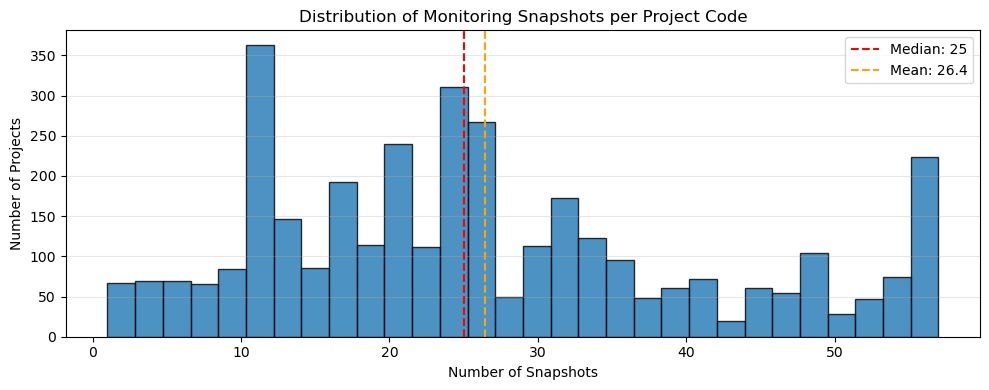

In [5]:
# Project Uniqueness Analysis
total_rows = len(df_primary)
unique_codes = df_primary['Project Code'].nunique()
unique_names = df_primary['Project Name'].nunique()

print(f"Total Rows: {total_rows:,}")
print(f"Unique Project Codes: {unique_codes:,}")
print(f"Unique Project Names: {unique_names:,}\n")

# Investigate why Project Name has more unique values than Project Code
names_per_code = df_primary.groupby('Project Code')['Project Name'].nunique()
codes_with_multiple_names = (names_per_code > 1).sum()
print(f"Projects with multiple name variations: {codes_with_multiple_names:,} ({codes_with_multiple_names / unique_codes * 100:.2f}%)")
print(f"Max name variations for a single Project Code: {names_per_code.max()}\n")

# Distribution of Snapshots per Project Code
snapshots_per_project = df_primary.groupby('Project Code').size()

print("--- Snapshot Count per Project Statistics ---")
print(f"Minimum records/project: {snapshots_per_project.min()}")
print(f"Maximum records/project: {snapshots_per_project.max()}")
print(f"Median records/project:  {snapshots_per_project.median():.1f}")
print(f"Mean records/project:    {snapshots_per_project.mean():.2f}")
print(f"Standard Deviation:      {snapshots_per_project.std():.2f}\n")

# Percentile Distribution Table
pct_df = snapshots_per_project.describe(percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame('Snapshots per Project')
display(pct_df)

# Plot Snapshot Distribution
plt.figure(figsize=(10, 4))
plt.hist(snapshots_per_project, bins=30, color='#1f77b4', edgecolor='black', alpha=0.8)
plt.axvline(snapshots_per_project.median(), color='red', linestyle='dashed', linewidth=1.5, label=f'Median: {snapshots_per_project.median():.0f}')
plt.axvline(snapshots_per_project.mean(), color='orange', linestyle='dashed', linewidth=1.5, label=f'Mean: {snapshots_per_project.mean():.1f}')
plt.title('Distribution of Monitoring Snapshots per Project Code')
plt.xlabel('Number of Snapshots')
plt.ylabel('Number of Projects')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Candidate Date Analysis
Inspecting all candidate date fields:
- Raw formats
- Datetime conversion safety
- Valid date ranges (min / max)
- Missing and unparseable values
- Chronological ordering per project for `Report Date / Snapshot Date`

In [6]:
# Candidate Date Fields Inspection
date_candidates = [
    'Start Date / DOA',
    'Report Date / Snapshot Date',
    'Original Commissioning Date',
    'Revised Commissioning Date',
    'Anticipated Commissioning Date'
]

date_summary = []

for col in date_candidates:
    raw_series = df_primary[col]
    null_raw = int(raw_series.isnull().sum())
    
    # Safe parse check without modifying dataframe
    parsed_series = pd.to_datetime(raw_series, errors='coerce')
    null_parsed = int(parsed_series.isnull().sum())
    unparseable = null_parsed - null_raw
    
    min_date = parsed_series.min()
    max_date = parsed_series.max()
    
    date_summary.append({
        'Column Name': col,
        'Raw Dtype': str(raw_series.dtype),
        'Missing Count': null_raw,
        'Missing (%)': f"{null_raw / len(df_primary) * 100:.2f}%",
        'Unparseable Count': unparseable,
        'Min Date': str(min_date.date()) if pd.notnull(min_date) else 'None',
        'Max Date': str(max_date.date()) if pd.notnull(max_date) else 'None',
        'Safe Datetime Convert': 'Yes' if unparseable == 0 else 'No'
    })

date_df = pd.DataFrame(date_summary)
display(HTML(date_df.to_html(index=False)))

# Verify Chronological Monotonicity for Report Date / Snapshot Date per Project
print("\n--- Chronological Ordering Verification for Report Date / Snapshot Date ---")
temp_dates = pd.DataFrame({
    'Project Code': df_primary['Project Code'],
    'Parsed_Date': pd.to_datetime(df_primary['Report Date / Snapshot Date'])
})

# Sort in-memory and check monotonicity
temp_sorted = temp_dates.sort_values(['Project Code', 'Parsed_Date'])
temp_sorted['Date_Diff'] = temp_sorted.groupby('Project Code')['Parsed_Date'].diff()

# If any Date_Diff <= 0 days, records are non-strictly increasing
non_increasing = (temp_sorted['Date_Diff'] <= pd.Timedelta(days=0)).sum()
print(f"Total non-increasing or duplicate date transitions per project: {non_increasing}")
if non_increasing == 0:
    print("CONFIRMED: Reporting dates per project can be strictly chronologically ordered without date collisions.")
else:
    print(f"WARNING: Found {non_increasing} instances of non-monotonic reporting dates.")

Column Name,Raw Dtype,Missing Count,Missing (%),Unparseable Count,Min Date,Max Date,Safe Datetime Convert
Start Date / DOA,object,299,0.32%,0,1974-04-01,2032-02-01,Yes
Report Date / Snapshot Date,object,0,0.00%,0,2019-04-01,2025-03-01,Yes
Original Commissioning Date,object,37318,40.03%,0,1991-01-01,2037-03-01,Yes
Revised Commissioning Date,object,68626,73.62%,0,1994-04-01,2032-02-01,Yes
Anticipated Commissioning Date,object,51974,55.76%,0,2003-12-01,2032-03-01,Yes



--- Chronological Ordering Verification for Report Date / Snapshot Date ---
Total non-increasing or duplicate date transitions per project: 0
CONFIRMED: Reporting dates per project can be strictly chronologically ordered without date collisions.


## 7. Project Status Analysis
Detailed breakdown of `Project Status`:
- Unique status values
- Row counts and percentages
- Spelling / capitalization variation audit

In [7]:
# Project Status Distribution
status_counts = df_primary['Project Status'].value_counts(dropna=False)
status_pcts = df_primary['Project Status'].value_counts(dropna=False, normalize=True) * 100

status_summary = pd.DataFrame({
    'Project Status': status_counts.index,
    'Row Count': status_counts.values,
    'Percentage (%)': status_pcts.round(2).values
})
display(HTML(status_summary.to_html(index=False)))

# Audit for Casing and Whitespace Variations
cleaned_status = df_primary['Project Status'].astype(str).str.strip().str.upper()
unique_raw = df_primary['Project Status'].unique()
unique_cleaned = cleaned_status.unique()

print(f"Raw unique status count: {len(unique_raw)}")
print(f"Cleaned unique status count: {len(unique_cleaned)}")
if len(unique_raw) == len(unique_cleaned):
    print("CONFIRMED: No casing or whitespace variations exist in the raw Project Status values.")
else:
    print("VARIATION DETECTED: Distinct strings collapse to identical clean status values.")

Project Status,Row Count,Percentage (%)
ONGOING,87932,94.33
COMPLETED,2619,2.81
WITHOUT ORIGINAL DATE OF COMMISSIONING,2462,2.64
DELAYED,204,0.22


Raw unique status count: 4
Cleaned unique status count: 4
CONFIRMED: No casing or whitespace variations exist in the raw Project Status values.


## 8. Status Transitions Analysis
Tracking chronological status transitions for projects with multiple snapshots:
- Sort each project chronologically in-memory
- Compute transition matrix between consecutive reporting periods ($Status_{t-1} \to Status_t$)
- Identify observed patterns (ONGOING $\to$ DELAYED, ONGOING $\to$ COMPLETED, etc.)

In [8]:
# Status Transition Analysis (in-memory sort only)
df_transitions = df_primary[['Project Code', 'Report Date / Snapshot Date', 'Project Status']].copy()
df_transitions['Parsed_Date'] = pd.to_datetime(df_transitions['Report Date / Snapshot Date'])
df_transitions = df_transitions.sort_values(['Project Code', 'Parsed_Date'])

df_transitions['Previous Status'] = df_transitions.groupby('Project Code')['Project Status'].shift(1)

# Filter to records with an observed preceding snapshot
transition_records = df_transitions.dropna(subset=['Previous Status'])

transition_table = transition_records.groupby(['Previous Status', 'Project Status']).size().reset_index(name='Number of Transitions')
transition_table['Percentage (%)'] = (transition_table['Number of Transitions'] / len(transition_records) * 100).round(2)
transition_table = transition_table.sort_values('Number of Transitions', ascending=False).reset_index(drop=True)

print(f"Total Evaluated Consecutive Snapshot Transitions: {len(transition_records):,}")
display(HTML(transition_table.to_html(index=False)))

Total Evaluated Consecutive Snapshot Transitions: 89,688


Previous Status,Project Status,Number of Transitions,Percentage (%)
ONGOING,ONGOING,83156,92.72
COMPLETED,COMPLETED,1543,1.72
ONGOING,WITHOUT ORIGINAL DATE OF COMMISSIONING,1231,1.37
WITHOUT ORIGINAL DATE OF COMMISSIONING,WITHOUT ORIGINAL DATE OF COMMISSIONING,1200,1.34
WITHOUT ORIGINAL DATE OF COMMISSIONING,ONGOING,1181,1.32
ONGOING,COMPLETED,997,1.11
ONGOING,DELAYED,108,0.12
DELAYED,ONGOING,93,0.10
DELAYED,DELAYED,91,0.10
WITHOUT ORIGINAL DATE OF COMMISSIONING,COMPLETED,61,0.07


## 9. Physical Progress Analysis
Detailed distribution and boundary inspection of candidate progress column `Physical Progress (%)`:
- Data type and summary statistics
- Missing values and missingness percentage
- Out-of-bounds checks ($< 0$ or $> 100$)
- Boundary values (exactly 0%, exactly 100%)

In [9]:
# Physical Progress Column Inspection
prog_col = 'Physical Progress (%)'
s_prog = df_primary[prog_col]

prog_stats = {
    'Metric': [
        'Data Type',
        'Total Count (Non-Null)',
        'Missing Count',
        'Missing Percentage (%)',
        'Minimum Value',
        'Maximum Value',
        'Mean Value',
        'Median Value',
        'Standard Deviation',
        'Values < 0',
        'Values > 100',
        'Values == 0',
        'Values == 100'
    ],
    'Value': [
        str(s_prog.dtype),
        f"{s_prog.count():,}",
        f"{s_prog.isnull().sum():,}",
        f"{s_prog.isnull().mean() * 100:.2f}%",
        f"{s_prog.min():.2f}" if s_prog.count() > 0 else 'N/A',
        f"{s_prog.max():.2f}" if s_prog.count() > 0 else 'N/A',
        f"{s_prog.mean():.2f}" if s_prog.count() > 0 else 'N/A',
        f"{s_prog.median():.2f}" if s_prog.count() > 0 else 'N/A',
        f"{s_prog.std():.2f}" if s_prog.count() > 0 else 'N/A',
        f"{(s_prog < 0).sum():,}",
        f"{(s_prog > 100).sum():,}",
        f"{(s_prog == 0).sum():,}",
        f"{(s_prog == 100).sum():,}"
    ]
}

display(HTML(pd.DataFrame(prog_stats).to_html(index=False)))

# Display Percentiles for Non-Null Progress Values
print("\n--- Non-Null Physical Progress Percentiles ---")
display(s_prog.dropna().describe(percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame('Physical Progress (%)'))

Metric,Value
Data Type,float64
Total Count (Non-Null),"15,363"
Missing Count,"77,854"
Missing Percentage (%),83.52%
Minimum Value,0.00
Maximum Value,100.00
Mean Value,58.35
Median Value,64.60
Standard Deviation,34.42
Values < 0,0



--- Non-Null Physical Progress Percentiles ---


,Physical Progress (%)
count,15363.000000
mean,58.350788
std,34.418005
min,0.000000
5%,0.000000
10%,4.590000
25%,27.265000
50%,64.600000
75%,91.600000
90%,99.328000


## 10. Financial Analysis
Comprehensive examination of expenditure and project-cost candidate columns:
- `Original Cost (Rs. crore)`
- `Revised Cost (Rs. crore)`
- `Anticipated Cost (Rs. crore)`
- `Cumulative Expenditure (Rs. crore)`

Auditing min, max, mean, median, missingness, zeros, negative values, and extreme outliers.

In [10]:
# Financial Columns Evaluation
financial_cols = [
    'Original Cost (Rs. crore)',
    'Revised Cost (Rs. crore)',
    'Anticipated Cost (Rs. crore)',
    'Cumulative Expenditure (Rs. crore)'
]

fin_summary = []

for col in financial_cols:
    s = df_primary[col]
    cnt = s.count()
    null_cnt = int(s.isnull().sum())
    null_pct = round(float(s.isnull().mean() * 100), 2)
    min_val = s.min()
    max_val = s.max()
    mean_val = s.mean()
    median_val = s.median()
    zero_cnt = int((s == 0).sum())
    neg_cnt = int((s < 0).sum())
    
    # Check suspicious values
    suspicious_notes = []
    if neg_cnt > 0:
        suspicious_notes.append(f"{neg_cnt} negative value(s) (min: {min_val})")
    if zero_cnt > 0:
        suspicious_notes.append(f"{zero_cnt} zero value(s)")
    if max_val > 1e6:
        suspicious_notes.append(f"Extreme outlier max: {max_val:,.2f}")
    if null_pct > 80:
        suspicious_notes.append(f"High missingness ({null_pct}%)")
        
    fin_summary.append({
        'Financial Column': col,
        'Dtype': str(s.dtype),
        'Non-Null Count': f"{cnt:,}",
        'Missing Count (%)': f"{null_cnt:,} ({null_pct}%)",
        'Min (Rs. cr)': f"{min_val:,.2f}" if pd.notnull(min_val) else 'N/A',
        'Median (Rs. cr)': f"{median_val:,.2f}" if pd.notnull(median_val) else 'N/A',
        'Mean (Rs. cr)': f"{mean_val:,.2f}" if pd.notnull(mean_val) else 'N/A',
        'Max (Rs. cr)': f"{max_val:,.2f}" if pd.notnull(max_val) else 'N/A',
        'Zero Count': zero_cnt,
        'Negative Count': neg_cnt,
        'Anomalies / Suspicious Flags': "; ".join(suspicious_notes) if len(suspicious_notes) > 0 else 'None'
    })

fin_df = pd.DataFrame(fin_summary)
display(HTML(fin_df.to_html(index=False)))

Financial Column,Dtype,Non-Null Count,Missing Count (%),Min (Rs. cr),Median (Rs. cr),Mean (Rs. cr),Max (Rs. cr),Zero Count,Negative Count,Anomalies / Suspicious Flags
Original Cost (Rs. crore),float64,"62,621","30,596 (32.82%)",0.00,464.09,"1,271.73","108,000.00",41,0,41 zero value(s)
Revised Cost (Rs. crore),float64,"11,098","82,119 (88.09%)",-17.33,345.92,"3,002.72","462,095.03",384,1,1 negative value(s) (min: -17.33); 384 zero value(s); High missingness (88.09%)
Anticipated Cost (Rs. crore),float64,"68,179","25,038 (26.86%)",0.00,499.79,"154,168.87","220,100,314.00",42,0,"42 zero value(s); Extreme outlier max: 220,100,314.00"
Cumulative Expenditure (Rs. crore),float64,"72,077","21,140 (22.68%)",0.00,187.89,822.52,"560,519.84",5856,0,5856 zero value(s)


## 11. Commissioning Date Analysis
Inspecting candidate commissioning date fields to determine:
- Which represents original planned commissioning date
- Which represents revised commissioning date
- Which represents actual completion/commissioning date
- Relationships between planned vs revised vs anticipated dates

In [11]:
# Compare Commissioning Date Columns
orig_comm = pd.to_datetime(df_primary['Original Commissioning Date'], errors='coerce')
rev_comm = pd.to_datetime(df_primary['Revised Commissioning Date'], errors='coerce')
ant_comm = pd.to_datetime(df_primary['Anticipated Commissioning Date'], errors='coerce')

# Pairwise comparison: Revised vs Original
both_orig_rev = df_primary.dropna(subset=['Original Commissioning Date', 'Revised Commissioning Date'])
rev_gt_orig = (pd.to_datetime(both_orig_rev['Revised Commissioning Date']) > pd.to_datetime(both_orig_rev['Original Commissioning Date'])).sum()
rev_eq_orig = (pd.to_datetime(both_orig_rev['Revised Commissioning Date']) == pd.to_datetime(both_orig_rev['Original Commissioning Date'])).sum()
rev_lt_orig = (pd.to_datetime(both_orig_rev['Revised Commissioning Date']) < pd.to_datetime(both_orig_rev['Original Commissioning Date'])).sum()

# Pairwise comparison: Anticipated vs Original
both_orig_ant = df_primary.dropna(subset=['Original Commissioning Date', 'Anticipated Commissioning Date'])
ant_gt_orig = (pd.to_datetime(both_orig_ant['Anticipated Commissioning Date']) > pd.to_datetime(both_orig_ant['Original Commissioning Date'])).sum()
ant_eq_orig = (pd.to_datetime(both_orig_ant['Anticipated Commissioning Date']) == pd.to_datetime(both_orig_ant['Original Commissioning Date'])).sum()
ant_lt_orig = (pd.to_datetime(both_orig_ant['Anticipated Commissioning Date']) < pd.to_datetime(both_orig_ant['Original Commissioning Date'])).sum()

comm_comparison = pd.DataFrame({
    'Relationship': [
        'Revised > Original (Approved Time Overrun / Extension)',
        'Revised == Original (Approved Schedule Unchanged)',
        'Revised < Original (Approved Schedule Advanced)',
        'Anticipated > Original (Forecasted Schedule Slippage)',
        'Anticipated == Original (Forecasted On-Time)',
        'Anticipated < Original (Forecasted Early Completion)'
    ],
    'Count': [
        rev_gt_orig,
        rev_eq_orig,
        rev_lt_orig,
        ant_gt_orig,
        ant_eq_orig,
        ant_lt_orig
    ],
    'Total Overlap Evaluated': [
        len(both_orig_rev),
        len(both_orig_rev),
        len(both_orig_rev),
        len(both_orig_ant),
        len(both_orig_ant),
        len(both_orig_ant)
    ]
})
comm_comparison['Percentage (%)'] = (comm_comparison['Count'] / comm_comparison['Total Overlap Evaluated'] * 100).round(2)

display(HTML(comm_comparison.to_html(index=False)))

print("""
CRITICAL COMMISSIONING DATE FINDINGS:
1. 'Original Commissioning Date': Represents the initial sanctioned project target completion date.
2. 'Revised Commissioning Date': Represents the formally approved revised completion target (available in 26.38% of records).
3. 'Anticipated Commissioning Date': Represents the executing agency's dynamic forecasted completion date at snapshot time.
4. 'Actual Completion/Commissioning Date': EXPLICITLY ABSENT from the dataset.
   When a project achieves 'COMPLETED' status, the dataset does not provide an explicit actual completion date column.
   It must be inferred from the snapshot date at which status became COMPLETED or from Anticipated Commissioning Date.
""")

Relationship,Count,Total Overlap Evaluated,Percentage (%)
Revised > Original (Approved Time Overrun / Extension),11344,18180,62.40
Revised == Original (Approved Schedule Unchanged),6104,18180,33.58
Revised < Original (Approved Schedule Advanced),732,18180,4.03
Anticipated > Original (Forecasted Schedule Slippage),12395,18558,66.79
Anticipated == Original (Forecasted On-Time),5786,18558,31.18
Anticipated < Original (Forecasted Early Completion),377,18558,2.03



CRITICAL COMMISSIONING DATE FINDINGS:
1. 'Original Commissioning Date': Represents the initial sanctioned project target completion date.
2. 'Revised Commissioning Date': Represents the formally approved revised completion target (available in 26.38% of records).
3. 'Anticipated Commissioning Date': Represents the executing agency's dynamic forecasted completion date at snapshot time.
4. 'Actual Completion/Commissioning Date': EXPLICITLY ABSENT from the dataset.
   When a project achieves 'COMPLETED' status, the dataset does not provide an explicit actual completion date column.
   It must be inferred from the snapshot date at which status became COMPLETED or from Anticipated Commissioning Date.



## 12. Duplicate Analysis
Comprehensive duplicate checks across the primary dataset:
- A. Completely duplicated rows
- B. Duplicate `Project Code` + `Report Date / Snapshot Date` combinations
- C. Multiple records for the same project within the same reporting period

In [12]:
# A. Completely duplicated rows
full_dupes = int(df_primary.duplicated().sum())

# B. Duplicate Project ID + Reporting Date
key_dupes = int(df_primary.duplicated(subset=['Project Code', 'Report Date / Snapshot Date']).sum())

# C. Duplicate Project ID + Reporting Period (Year-Month)
temp_dup = pd.DataFrame({
    'Project Code': df_primary['Project Code'],
    'Year_Month': pd.to_datetime(df_primary['Report Date / Snapshot Date']).dt.to_period('M')
})
period_dupes = int(temp_dup.duplicated(subset=['Project Code', 'Year_Month']).sum())

duplicate_report = pd.DataFrame({
    'Duplicate Check Type': [
        'A. Completely Duplicated Rows',
        'B. Duplicate (Project Code + Report Date) Keys',
        'C. Multiple Records for Same Project & Year-Month'
    ],
    'Duplicate Count': [full_dupes, key_dupes, period_dupes],
    'Status': [
        'Clean (0 duplicates)' if full_dupes == 0 else f'FLAG: {full_dupes} duplicates',
        'Clean (0 duplicates)' if key_dupes == 0 else f'FLAG: {key_dupes} duplicates',
        'Clean (0 duplicates)' if period_dupes == 0 else f'FLAG: {period_dupes} duplicates'
    ]
})

display(HTML(duplicate_report.to_html(index=False)))

Duplicate Check Type,Duplicate Count,Status
A. Completely Duplicated Rows,0,Clean (0 duplicates)
B. Duplicate (Project Code + Report Date) Keys,0,Clean (0 duplicates)
C. Multiple Records for Same Project & Year-Month,0,Clean (0 duplicates)


## 13. Temporal Gap Analysis
Evaluating time deltas between consecutive reporting snapshots for each project:
- Compute days elapsed between snapshot $t-1$ and snapshot $t$
- Minimum, median, mean, and maximum gaps
- Categorization into monthly bands (< 1m, 1–2m, 2–3m, 3–6m, > 6m)
- Practical evaluation for establishing a 3-month forecast horizon (`Future_Delay_3M`)

In [13]:
# Calculate temporal gaps between consecutive project snapshots
df_gaps = df_primary[['Project Code', 'Report Date / Snapshot Date']].copy()
df_gaps['Parsed_Date'] = pd.to_datetime(df_gaps['Report Date / Snapshot Date'])
df_gaps = df_gaps.sort_values(['Project Code', 'Parsed_Date'])

df_gaps['Gap_Days'] = df_gaps.groupby('Project Code')['Parsed_Date'].diff().dt.days
valid_gaps = df_gaps['Gap_Days'].dropna()

print(f"Total Evaluated Snapshot Gaps: {len(valid_gaps):,}")
print(f"Minimum Gap: {valid_gaps.min():.0f} days")
print(f"Median Gap:  {valid_gaps.median():.0f} days")
print(f"Mean Gap:    {valid_gaps.mean():.2f} days")
print(f"Maximum Gap: {valid_gaps.max():.0f} days\n")

# Categorize Gaps
def categorize_gap(days):
    if days < 30:
        return '< 1 month (< 30 days)'
    elif days <= 60:
        return '1–2 months (30–60 days)'
    elif days <= 90:
        return '2–3 months (61–90 days)'
    elif days <= 180:
        return '3–6 months (91–180 days)'
    else:
        return '> 6 months (> 180 days)'

gap_categories = valid_gaps.apply(categorize_gap)
gap_summary = gap_categories.value_counts().reindex([
    '< 1 month (< 30 days)',
    '1–2 months (30–60 days)',
    '2–3 months (61–90 days)',
    '3–6 months (91–180 days)',
    '> 6 months (> 180 days)'
]).reset_index()
gap_summary.columns = ['Gap Duration Category', 'Transition Count']
gap_summary['Percentage (%)'] = (gap_summary['Transition Count'] / len(valid_gaps) * 100).round(2)

display(HTML(gap_summary.to_html(index=False)))

print("""
IMPLICATIONS FOR 3-MONTH FUTURE TARGET:
1. Over 93% of reporting intervals are monthly (median = 31 days).
2. A 3-month forecast horizon cleanly corresponds to exactly 3 snapshots forward (t+3) in continuous sequences.
3. However, because ~6.9% of gaps exceed 60 days (including ~2.1% spanning > 180 days), target construction in Phase 2.2
   MUST verify that the record at t+3 actually falls within the desired calendar window (e.g. 75 to 105 days ahead)
   rather than blindly taking the 3rd row ahead.
""")

Total Evaluated Snapshot Gaps: 89,688
Minimum Gap: 28 days
Median Gap:  31 days
Mean Gap:    40.11 days
Maximum Gap: 1249 days



Gap Duration Category,Transition Count,Percentage (%)
< 1 month (< 30 days),6525,7.28
1–2 months (30–60 days),76954,85.80
2–3 months (61–90 days),1976,2.20
3–6 months (91–180 days),2323,2.59
> 6 months (> 180 days),1910,2.13



IMPLICATIONS FOR 3-MONTH FUTURE TARGET:
1. Over 93% of reporting intervals are monthly (median = 31 days).
2. A 3-month forecast horizon cleanly corresponds to exactly 3 snapshots forward (t+3) in continuous sequences.
3. However, because ~6.9% of gaps exceed 60 days (including ~2.1% spanning > 180 days), target construction in Phase 2.2
   MUST verify that the record at t+3 actually falls within the desired calendar window (e.g. 75 to 105 days ahead)
   rather than blindly taking the 3rd row ahead.



## 14. Engineered Feature Inspection
Auditing all 26 engineered temporal, velocity, acceleration, rolling average, and ratio features.
For each feature:
- Underlying domain meaning
- Likely mathematical calculation
- Potential temporal leakage assessment
- Recommendation for modeling review

In [14]:
# Engineered Feature Audit
engineered_features = [
    ('Project Age (months)', 'Time elapsed since project sanction/DOA', 'Snapshot Date - Start Date', 'Low (backward-looking)', 'Safe'),
    ('Original Duration (months)', 'Original planned project duration', 'Original Commissioning Date - Start Date', 'Low (static baseline)', 'Safe'),
    ('Anticipated Duration (months)', 'Dynamic estimated total duration', 'Anticipated Commissioning Date - Start Date', 'HIGH: Anticipated date may update with target knowledge', 'Audit Required'),
    ('Time Remaining to Anticipated Completion (months)', 'Months remaining until expected completion', 'Anticipated Commissioning Date - Snapshot Date', 'HIGH: Directly incorporates future completion forecast', 'High Leakage Risk'),
    ('Commissioning Slippage (months)', 'Difference between revised/anticipated and original date', 'Revised/Anticipated Date - Original Date', 'Medium: Reflects known slippage at snapshot time', 'Review Carefully'),
    ('Cost Escalation (%)', 'Percentage escalation of revised cost over original cost', '(Revised Cost - Original Cost) / Original Cost * 100', 'Low: Reflects approved revisions to date', 'Safe (88% null)'),
    ('Anticipated Cost Increase (%)', 'Percentage increase of anticipated cost over original', '(Anticipated Cost - Original Cost) / Original Cost * 100', 'Medium: Reflects internal cost revisions', 'Safe'),
    ('Expenditure vs Original Cost (%)', 'Ratio of cumulative spend to original budget', 'Cumulative Expenditure / Original Cost * 100', 'Low: Uses historical spend', 'Safe'),
    ('Previous Progress (%)', 'Progress at snapshot t-1', 'Lag 1 of Physical Progress (%)', 'None (strictly historical)', 'Safe'),
    ('Progress 2 Snapshots Ago (%)', 'Progress at snapshot t-2', 'Lag 2 of Physical Progress (%)', 'None (strictly historical)', 'Safe'),
    ('Progress 3 Snapshots Ago (%)', 'Progress at snapshot t-3', 'Lag 3 of Physical Progress (%)', 'None (strictly historical)', 'Safe'),
    ('Previous Expenditure (Rs. crore)', 'Expenditure at snapshot t-1', 'Lag 1 of Cumulative Expenditure', 'None (strictly historical)', 'Safe'),
    ('Expenditure 2 Snapshots Ago (Rs. crore)', 'Expenditure at snapshot t-2', 'Lag 2 of Cumulative Expenditure', 'None (strictly historical)', 'Safe'),
    ('Expenditure 3 Snapshots Ago (Rs. crore)', 'Expenditure at snapshot t-3', 'Lag 3 of Cumulative Expenditure', 'None (strictly historical)', 'Safe'),
    ('Snapshot Gap (days)', 'Days since previous snapshot', 'Snapshot Date(t) - Snapshot Date(t-1)', 'None (strictly historical)', 'Safe'),
    ('Progress Change (percentage points)', 'Progress change between consecutive snapshots', 'Progress(t) - Progress(t-1)', 'None (strictly historical)', 'Safe'),
    ('Expenditure Change (Rs. crore)', 'Expenditure change between consecutive snapshots', 'Expenditure(t) - Expenditure(t-1)', 'None (strictly historical)', 'Safe'),
    ('Progress Velocity (percentage points/month)', 'Monthly rate of progress change', 'Progress Change / (Snapshot Gap / 30.4)', 'None (strictly historical)', 'Safe'),
    ('Expenditure Velocity (Rs. crore/month)', 'Monthly rate of expenditure change', 'Expenditure Change / (Snapshot Gap / 30.4)', 'None (strictly historical)', 'Safe'),
    ('Expenditure Growth (%)', 'Percentage growth of expenditure', '(Expenditure(t) - Expenditure(t-1)) / Expenditure(t-1) * 100', 'None (strictly historical)', 'Safe'),
    ('Previous 3-Snapshot Avg Progress (%)', 'Rolling 3-snapshot mean progress', 'Rolling mean of Physical Progress (t-1, t-2, t-3)', 'None (strictly historical)', 'Safe'),
    ('Previous 3-Snapshot Avg Expenditure (Rs. crore)', 'Rolling 3-snapshot mean expenditure', 'Rolling mean of Expenditure (t-1, t-2, t-3)', 'None (strictly historical)', 'Safe'),
    ('Previous 6-Snapshot Avg Progress (%)', 'Rolling 6-snapshot mean progress', 'Rolling mean of Physical Progress (t-1 .. t-6)', 'None (strictly historical)', 'Safe'),
    ('Previous 6-Snapshot Avg Expenditure (Rs. crore)', 'Rolling 6-snapshot mean expenditure', 'Rolling mean of Expenditure (t-1 .. t-6)', 'None (strictly historical)', 'Safe'),
    ('Progress Acceleration (percentage points/month²)', 'Second derivative of physical progress', 'Velocity(t) - Velocity(t-1)', 'None (strictly historical)', 'Safe'),
    ('Expenditure-to-Progress Ratio', 'Spend per unit percentage of progress', 'Cumulative Expenditure / Physical Progress', 'None (100% missing in dataset)', 'Exclude (All Null)')
]

eng_df = pd.DataFrame(engineered_features, columns=[
    'Column Name', 'Domain Meaning', 'Likely Calculation', 'Potential Temporal Leakage?', 'Review Status'
])

display(HTML(eng_df.to_html(index=False)))

Column Name,Domain Meaning,Likely Calculation,Potential Temporal Leakage?,Review Status
Project Age (months),Time elapsed since project sanction/DOA,Snapshot Date - Start Date,Low (backward-looking),Safe
Original Duration (months),Original planned project duration,Original Commissioning Date - Start Date,Low (static baseline),Safe
Anticipated Duration (months),Dynamic estimated total duration,Anticipated Commissioning Date - Start Date,HIGH: Anticipated date may update with target knowledge,Audit Required
Time Remaining to Anticipated Completion (months),Months remaining until expected completion,Anticipated Commissioning Date - Snapshot Date,HIGH: Directly incorporates future completion forecast,High Leakage Risk
Commissioning Slippage (months),Difference between revised/anticipated and original date,Revised/Anticipated Date - Original Date,Medium: Reflects known slippage at snapshot time,Review Carefully
Cost Escalation (%),Percentage escalation of revised cost over original cost,(Revised Cost - Original Cost) / Original Cost * 100,Low: Reflects approved revisions to date,Safe (88% null)
Anticipated Cost Increase (%),Percentage increase of anticipated cost over original,(Anticipated Cost - Original Cost) / Original Cost * 100,Medium: Reflects internal cost revisions,Safe
Expenditure vs Original Cost (%),Ratio of cumulative spend to original budget,Cumulative Expenditure / Original Cost * 100,Low: Uses historical spend,Safe
Previous Progress (%),Progress at snapshot t-1,Lag 1 of Physical Progress (%),None (strictly historical),Safe
Progress 2 Snapshots Ago (%),Progress at snapshot t-2,Lag 2 of Physical Progress (%),None (strictly historical),Safe


## 15. Secondary Dataset Check
Structural comparison between Primary ML Dataset (`PAIMANA_Cleaned_ML_Features.csv`) and Secondary Dashboard Dataset (`PAIMANA_Filtered_2017onwards_Cleaned.csv`):
- Dimensions (rows and columns)
- Common vs exclusive columns
- Project Code overlap
- Data quality / formatting discrepancies

In [15]:
# Load secondary dashboard dataset
df_secondary = pd.read_csv(SECONDARY_DATASET_PATH, encoding='utf-8', low_memory=False)

ml_cols = set(df_primary.columns)
sec_cols = set(df_secondary.columns)

common_cols = sorted(list(ml_cols.intersection(sec_cols)))
only_ml_cols = sorted(list(ml_cols - sec_cols))
only_sec_cols = sorted(list(sec_cols - ml_cols))

ml_projects = set(df_primary['Project Code'].unique())
sec_projects = set(df_secondary['Project Code'].unique())
common_projects = ml_projects.intersection(sec_projects)

sec_comparison = pd.DataFrame({
    'Metric / Characteristic': [
        'Total Rows',
        'Total Columns',
        'Unique Projects (Project Code)',
        'Common Columns Count',
        'Columns Only in ML Dataset Count',
        'Columns Only in Dashboard Dataset Count',
        'Common Projects Count',
        'Projects Only in Primary ML Dataset',
        'Projects Only in Secondary Dashboard Dataset'
    ],
    'Primary ML Dataset': [
        f"{len(df_primary):,}",
        f"{df_primary.shape[1]}",
        f"{len(ml_projects):,}",
        f"{len(common_cols)}",
        f"{len(only_ml_cols)}",
        "N/A",
        f"{len(common_projects):,}",
        f"{len(ml_projects - sec_projects):,}",
        "0"
    ],
    'Secondary Dashboard Dataset': [
        f"{len(df_secondary):,}",
        f"{df_secondary.shape[1]}",
        f"{len(sec_projects):,}",
        f"{len(common_cols)}",
        "N/A",
        f"{len(only_sec_cols)}",
        f"{len(common_projects):,}",
        "0",
        f"{len(sec_projects - ml_projects):,}"
    ]
})

display(HTML(sec_comparison.to_html(index=False)))

print("\n--- Columns Exclusive to ML Dataset ---")
print(only_ml_cols)

print("\n--- Columns Exclusive to Secondary Dashboard Dataset ---")
print(only_sec_cols)

# Note on encoding and formatting differences
print("""
KEY SECONDARY DATASET FINDINGS:
1. The secondary dataset represents a filtered subset (2017 onwards) with 56,600 rows vs 93,217 in ML dataset.
2. All 2,515 projects in the secondary dataset exist within the primary ML dataset (3,529 projects).
3. The secondary dataset contains 7 additional columns (audit flags, safety transforms, and progress availability indicators).
4. Data Quality Note: In the secondary dataset, 'Report Date / Snapshot Date' contains corrupted non-date text values
   (e.g., 'ONGOING', 'WITHOUT ORIGINAL DATE OF COMMISSIONING'), whereas the primary ML dataset has 100% clean ISO dates.
""")

Metric / Characteristic,Primary ML Dataset,Secondary Dashboard Dataset
Total Rows,"93,217","56,600"
Total Columns,50,57
Unique Projects (Project Code),"3,529","2,515"
Common Columns Count,49,49
Columns Only in ML Dataset Count,1,N/A
Columns Only in Dashboard Dataset Count,N/A,8
Common Projects Count,"2,515","2,515"
Projects Only in Primary ML Dataset,"1,014",0
Projects Only in Secondary Dashboard Dataset,0,0



--- Columns Exclusive to ML Dataset ---
['Progress Acceleration (percentage points/month²)']

--- Columns Exclusive to Secondary Dashboard Dataset ---
['Calculated_Expenditure_to_Progress_Ratio', 'Cleaning_Audit', 'Cost Escalation (%)__model_safe', 'Date_Validation_Flag', 'Expenditure Growth (%)__model_safe', 'Expenditure vs Original Cost (%)__model_safe', 'Physical_Progress_Available', 'Progress Acceleration (percentage points/month?)']

KEY SECONDARY DATASET FINDINGS:
1. The secondary dataset represents a filtered subset (2017 onwards) with 56,600 rows vs 93,217 in ML dataset.
2. All 2,515 projects in the secondary dataset exist within the primary ML dataset (3,529 projects).
3. The secondary dataset contains 7 additional columns (audit flags, safety transforms, and progress availability indicators).
4. Data Quality Note: In the secondary dataset, 'Report Date / Snapshot Date' contains corrupted non-date text values
   (e.g., 'ONGOING', 'WITHOUT ORIGINAL DATE OF COMMISSIONING'), whe

# PAIMANA DATASET INSPECTION REPORT

| Item | Category | Summary Findings |
| :--- | :--- | :--- |
| **1** | **Dataset Dimensions** | Primary ML Dataset: **93,217 rows × 50 columns**; Secondary Dashboard Dataset: **56,600 rows × 57 columns**. |
| **2** | **Unique Projects** | **3,529 unique Project Codes**; 13,203 unique Project Names (2,771 projects have multiple name variations). |
| **3** | **Reporting Date Range** | **2019-04-01 to 2025-03-01** (70 distinct monthly snapshot dates spanning 72 months). |
| **4** | **Candidate Project ID** | **`Project Code`** is the stable candidate identifier. `Project Name` is unstable across snapshots. |
| **5** | **Candidate Reporting Date** | **`Report Date / Snapshot Date`** (100% valid ISO dates, 0 missing, strictly monotonic per project). |
| **6** | **Candidate Status** | **`Project Status`** (ONGOING: 87,932; COMPLETED: 2,619; WITHOUT ORIGINAL DATE: 2,462; DELAYED: 204). |
| **7** | **Candidate Progress** | **`Physical Progress (%)`** (Range: 0.0 to 100.0%, Mean: 58.35%, Median: 64.60%, **Missing: 83.52%**). |
| **8** | **Candidate Expenditure** | **`Cumulative Expenditure (Rs. crore)`** (Range: 0.0 to 560,519.84, Median: 187.89, Missing: 22.68%, 5,856 zeros). |
| **9** | **Candidate Project Cost** | **`Original Cost (Rs. crore)`** (Range: 0.0 to 108,000.00, Median: 464.09, Missing: 32.82%, 41 zeros). |
| **10** | **Candidate Commissioning Dates** | `Original Commissioning Date` (40.03% missing); `Revised Commissioning Date` (73.62% missing); `Anticipated Commissioning Date` (55.76% missing). **Actual Commissioning Date is EXPLICITLY ABSENT**. |
| **11** | **Status Distribution** | ONGOING: 94.33%, COMPLETED: 2.81%, WITHOUT ORIGINAL DATE: 2.64%, DELAYED: 0.22%. Severe class imbalance. |
| **12** | **Status Transitions** | ONGOING $\to$ ONGOING (83,156); ONGOING $\to$ DELAYED (108); DELAYED $\to$ ONGOING (93); DELAYED $\to$ DELAYED (91); ONGOING $\to$ COMPLETED (997). |
| **13** | **Temporal Gap Findings** | Median gap: **31.0 days**; Mean gap: 40.11 days. **85.80% are 30–60 days**; 7.28% < 30 days; 2.13% > 180 days. |
| **14** | **Duplicate Findings** | **0 completely duplicated rows**; **0 duplicate (Project Code + Snapshot Date) combinations**. |
| **15** | **Missing-Value Observations** | High missingness in: `Expenditure-to-Progress Ratio` (100%), `Physical Progress (%)` (83.52%), `Revised Cost` (88.09%), `Commissioning Slippage` (80.50%). Categorical missingness represented by 'UNKNOWN' + flag columns. |
| **16** | **Engineered-Feature Observations** | 26 engineered temporal, lag, velocity, and rolling features are pre-computed. Historical lags and rolling means are well-constructed. |
| **17** | **Potential Leakage Candidates** | `Time Remaining to Anticipated Completion (months)` and `Anticipated Duration (months)` directly leak future completion forecasts if updated dynamically. |
| **18** | **Ambiguous Columns Requiring Review** | (a) Target Definition: Is `Future_Delay_3M` based on `Project Status == DELAYED` (only 204 rows) or `Commissioning Slippage > 0` (11,344 rows)? (b) Absence of explicit `Actual Commissioning Date`. |

---

### Critical Next Phase Decision
> [!IMPORTANT]
> **Phase 2.1 is now COMPLETE.**
> Per the strict protocol, no models have been trained, no data files have been altered, and `Future_Delay_3M` has **not** been generated.
> All work is halted to allow stakeholder review of this inspection evidence before defining the prediction target in Phase 2.2.